<a href="https://colab.research.google.com/github/sampath0711/DEEP-LEARNING/blob/main/Skill/Skill6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Setup and configuration

In [1]:
import os, json, random, shutil, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

try:
    import yaml
except ImportError:
    yaml = None

random.seed(42); np.random.seed(42)
plt.rcParams["figure.dpi"] = 110

# ---------------- CONFIG ----------------
DATASET_DIR = "/content/VisionPort_Dataset"
OUTPUT_DIR  = "/content/audit_output"
CLASS_NAMES = None            # e.g. ["person","car","bus","motorcycle","bicycle"]; None -> read classes.txt / data.yaml

# Image-quality thresholds (from the slide: Blur > 100 sharp, < 100 blurry)
MIN_WIDTH, MIN_HEIGHT = 320, 240
DARK_THRESHOLD   = 40         # mean gray (0 = dark, 255 = bright)
BRIGHT_THRESHOLD = 215
CONTRAST_MIN     = 25         # std-dev of gray; lower = washed out
BLUR_THRESHOLD   = 100.0      # Laplacian variance
NOISE_THRESHOLD  = 10.0       # estimated noise sigma

# Annotation checks
TINY_BOX_AREA = 0.0001        # normalised area
SHAPE_K       = 3.0           # strictness of shape-outlier check (higher = fewer flags)
N_SAMPLES     = 8
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
# ----------------------------------------
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Dataset collection: load the dataset
Choose ONE source and run the cell.

In [2]:
SOURCE = "upload"   # "upload" (zip) | "drive" | "existing"

if SOURCE == "upload":
    from google.colab import files
    up = files.upload()                                   # pick VisionPort_Dataset.zip
    zname = list(up.keys())[0]
    with zipfile.ZipFile(zname) as z:
        z.extractall("/content")
elif SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    DATASET_DIR = "/content/drive/MyDrive/VisionPort_Dataset"   # <- change if needed

# auto-locate the dataset root (folder that has classes.txt or an images/ folder)
cands = [p.parent for p in Path("/content").rglob("classes.txt") if "VisionPort" in str(p) or "dataset" in str(p).lower()]
if not Path(DATASET_DIR).exists() and cands:
    DATASET_DIR = str(cands[0])
root = Path(DATASET_DIR)
print("Dataset root:", root)

Saving VisionPort_Dataset.zip to VisionPort_Dataset.zip
Dataset root: /content/VisionPort_Dataset


## 3. Dataset structure and class names

In [3]:
def tree(path, depth=0, max_depth=2):
    for p in sorted(path.iterdir()):
        if p.is_dir():
            n = sum(1 for f in p.iterdir() if f.is_file())
            print("  " * depth + f"📁 {p.name}/" + (f"  ({n} files)" if n else ""))
            if depth < max_depth: tree(p, depth + 1, max_depth)
        elif depth == 0:
            print("  " * depth + f"📄 {p.name}")
tree(root)

names = CLASS_NAMES
if names is None and (root / "classes.txt").exists():
    names = [l.strip() for l in open(root / "classes.txt") if l.strip()]
    print("\nClass names read from classes.txt")
if names is None and yaml is not None:
    for y in root.rglob("*.yaml"):
        try:
            n = yaml.safe_load(open(y)).get("names")
            if isinstance(n, dict): n = [n[k] for k in sorted(n)]
            if n: names = list(n); print("\nClass names read from", y.name); break
        except Exception:
            pass
NC = len(names) if names else None
print("Classes:", {i: n for i, n in enumerate(names)} if names else "unknown (will infer from labels)")

📄 README.txt
📄 classes.txt
📄 data.yaml
📁 images/
  📁 test/  (36 files)
  📁 train/  (170 files)
  📁 val/  (36 files)
📁 labels/
  📁 test/  (36 files)
  📁 train/  (167 files)
  📁 val/  (36 files)

Class names read from classes.txt
Classes: {0: 'person', 1: 'car', 2: 'bus', 3: 'motorcycle', 4: 'bicycle'}


## 4. The audit scan
For every image: resolution, brightness, contrast, blur, noise and corruption. For every label file: missing or empty, malformed lines, invalid boxes, duplicate boxes.

In [4]:
def label_path_for(img: Path) -> Path:
    parts = list(img.parts)
    for i in range(len(parts) - 1, -1, -1):
        if parts[i] == "images":
            parts[i] = "labels"; break
    return Path(*parts).with_suffix(".txt")

def split_of(p: Path) -> str:
    for part in p.parts:
        if part.lower() in {"train", "val", "valid", "validation", "test"}:
            return "val" if part.lower() in {"valid", "validation"} else part.lower()
    return "all"

def estimate_noise(gray):
    """Immerkaer fast noise-sigma estimate (higher = noisier)."""
    h, w = gray.shape
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float64)
    conv = cv2.filter2D(gray.astype(np.float64), -1, k)[1:-1, 1:-1]
    return float(np.sqrt(np.pi / 2) * np.abs(conv).sum() / (6 * (w - 2) * (h - 2)))

images = sorted(p for p in root.rglob("*") if p.suffix.lower() in IMG_EXT)
all_label_files = sorted(p for p in root.rglob("*.txt")
                         if "labels" in p.parts and p.name.lower() not in {"classes.txt", "readme.txt"})
print(f"Found {len(images)} images and {len(all_label_files)} label files")

issues, img_rows, box_rows = [], [], []
def add_issue(file, split, kind, detail=""):
    issues.append({"file": str(file), "split": split, "issue": kind, "detail": detail})

for img in images:
    split = split_of(img)
    row = {"image": str(img), "name": img.name, "split": split, "width": None, "height": None,
           "corrupt": False, "size_kb": round(img.stat().st_size / 1024, 1),
           "brightness": None, "contrast": None, "blur_var": None, "noise": None,
           "quality": "Good", "quality_reasons": "", "has_label": False, "n_boxes": 0}
    reasons = []

    try:
        with Image.open(img) as im: im.verify()
        with Image.open(img) as im: row["width"], row["height"] = im.size
    except Exception as e:
        row["corrupt"] = True; reasons.append("corrupt")
        add_issue(img, split, "corrupt image", str(e)[:80])

    if not row["corrupt"]:
        g = cv2.imread(str(img), cv2.IMREAD_GRAYSCALE)
        if g is not None:
            row["brightness"] = float(g.mean())
            row["contrast"]   = float(g.std())
            row["blur_var"]   = float(cv2.Laplacian(g, cv2.CV_64F).var())
            row["noise"]      = estimate_noise(g)
            if row["width"] < MIN_WIDTH or row["height"] < MIN_HEIGHT:
                reasons.append("low resolution"); add_issue(img, split, "low resolution", f"{row['width']}x{row['height']}")
            if row["brightness"] < DARK_THRESHOLD:
                reasons.append("too dark"); add_issue(img, split, "too dark", f"mean={row['brightness']:.0f}")
            elif row["brightness"] > BRIGHT_THRESHOLD:
                reasons.append("too bright"); add_issue(img, split, "too bright", f"mean={row['brightness']:.0f}")
            if row["contrast"] < CONTRAST_MIN:
                reasons.append("low contrast"); add_issue(img, split, "low contrast", f"std={row['contrast']:.0f}")
            if row["blur_var"] < BLUR_THRESHOLD:
                reasons.append("blurry"); add_issue(img, split, "blurry", f"lap_var={row['blur_var']:.0f}")
            if row["noise"] > NOISE_THRESHOLD:
                reasons.append("noisy"); add_issue(img, split, "noisy", f"sigma={row['noise']:.1f}")
    if reasons:
        row["quality"] = "Review/Remove"; row["quality_reasons"] = ", ".join(reasons)

    lp = label_path_for(img)
    if not lp.exists():
        add_issue(img, split, "missing label file", str(lp))
    else:
        row["has_label"] = True
        lines = [l.strip() for l in open(lp).read().splitlines() if l.strip()]
        if not lines:
            add_issue(lp, split, "empty label file", "no objects")
        seen = set()
        for ln, line in enumerate(lines, 1):
            tok = line.split()
            b = {"image": img.name, "split": split, "line": ln, "cls": None, "x": None, "y": None,
                 "w": None, "h": None, "img_w": row["width"], "img_h": row["height"], "valid": True}
            if len(tok) != 5:
                add_issue(lp, split, "malformed line", f"line {ln}: expected 5 values, got {len(tok)}")
                b["valid"] = False; box_rows.append(b); continue
            try:
                c = int(float(tok[0])); x, y, w, h = map(float, tok[1:])
            except ValueError:
                add_issue(lp, split, "non-numeric value", f"line {ln}: {line[:50]}")
                b["valid"] = False; box_rows.append(b); continue
            b.update(cls=c, x=x, y=y, w=w, h=h)
            bad = []
            if c < 0 or (NC is not None and c >= NC): bad.append(f"class id {c} out of range")
            if not all(0 <= v <= 1 for v in (x, y, w, h)): bad.append("coordinate outside 0-1")
            if w <= 0 or h <= 0: bad.append("zero/negative width or height")
            elif (x - w/2 < -0.01) or (x + w/2 > 1.01) or (y - h/2 < -0.01) or (y + h/2 > 1.01):
                bad.append("box extends outside image")
            if w > 0 and h > 0 and w * h < TINY_BOX_AREA:
                add_issue(lp, split, "tiny box", f"line {ln}: area={w*h:.6f}")
            key = (c, round(x, 4), round(y, 4), round(w, 4), round(h, 4))
            if key in seen: bad.append("duplicate box")
            seen.add(key)
            for msg in bad: add_issue(lp, split, "invalid box", f"line {ln}: {msg}")
            if bad: b["valid"] = False
            box_rows.append(b); row["n_boxes"] += 1
    img_rows.append(row)

expected = {label_path_for(i) for i in images}
for lp in all_label_files:
    if lp not in expected:
        add_issue(lp, split_of(lp), "label without image", "orphan label")

df_img, df_box = pd.DataFrame(img_rows), pd.DataFrame(box_rows)
img_lookup = {(r["split"], r["name"]): Path(r["image"]) for r in img_rows}
if NC is None and len(df_box):
    NC = int(df_box["cls"].dropna().max()) + 1; names = [str(i) for i in range(NC)]
names = names or []
print(f"Scanned {len(df_img)} images and {len(df_box)} boxes")

Found 242 images and 239 label files
Scanned 242 images and 1291 boxes


In [5]:
flagged_boxes = set()     # (split, image name, line)
if len(df_box):
    vb = df_box[df_box["valid"] & df_box["cls"].notna() & df_box["img_w"].notna()].copy()
    vb["cls"] = vb["cls"].astype(int)
    vb["log_ar"] = np.log((vb["w"] * vb["img_w"]) / (vb["h"] * vb["img_h"]))
    for c, g in vb.groupby("cls"):
        if len(g) < 8: continue
        q1, q3 = g["log_ar"].quantile([0.25, 0.75]); med = g["log_ar"].median()
        iqr = max(q3 - q1, 0.08)
        lo, hi = q1 - SHAPE_K * iqr, q3 + SHAPE_K * iqr
        for _, r in g[(g["log_ar"] < lo) | (g["log_ar"] > hi)].iterrows():
            flagged_boxes.add((r["split"], r["image"], int(r["line"])))
            cname = names[c] if c < len(names) else str(c)
            add_issue(label_path_for(img_lookup[(r["split"], r["image"])]),
                      r["split"], "suspicious box shape",
                      f"line {int(r['line'])}: labelled '{cname}', aspect {np.exp(r['log_ar']):.2f} vs typical {np.exp(med):.2f} (wrong label or partial box?)")
print(f"Flagged {len(flagged_boxes)} boxes for manual review")

df_issues = pd.DataFrame(issues)

Flagged 11 boxes for manual review


## 6. Class distribution analysis

Class-frequency counts (boxes):
class_name
car           662
person        304
motorcycle    157
bus           116
bicycle        49
id_9            1

Images containing each class:
class_name
car           217
person        163
motorcycle    110
bus            93
bicycle        43
id_9            1


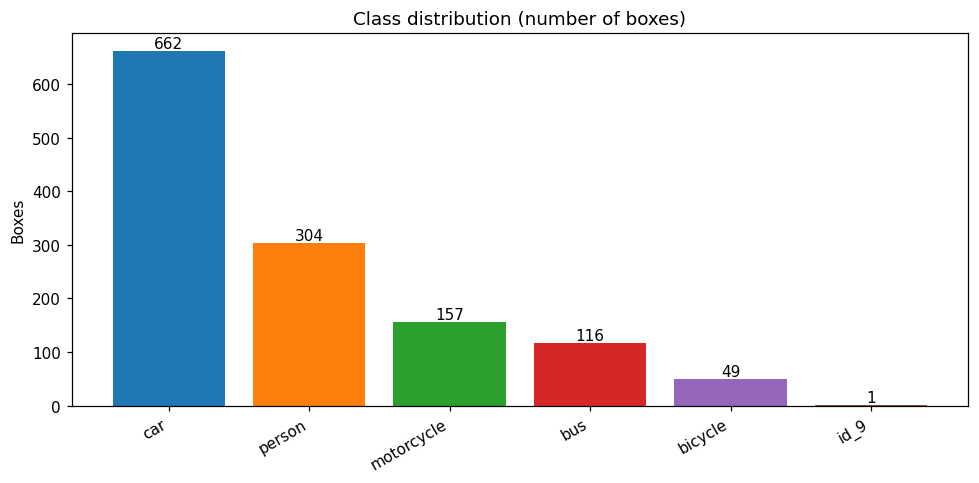

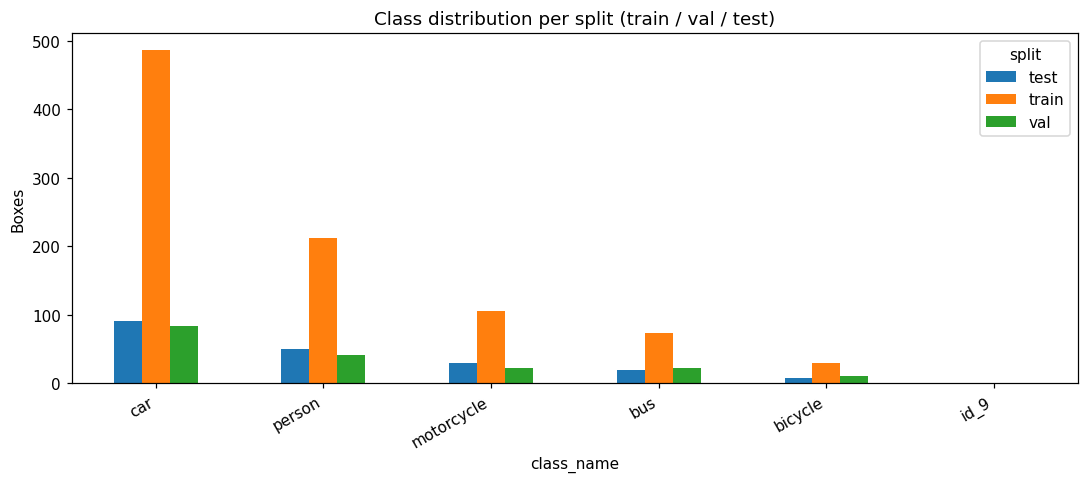

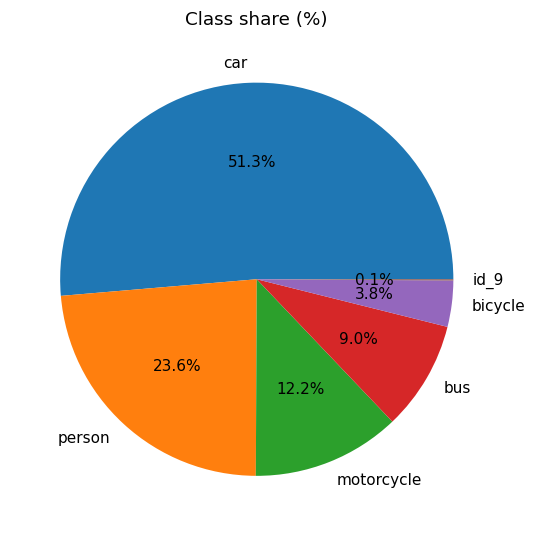

In [6]:
if len(df_box):
    boxes = df_box.dropna(subset=["cls"]).copy()
    boxes["cls"] = boxes["cls"].astype(int)
    boxes["class_name"] = boxes["cls"].apply(lambda c: names[c] if 0 <= c < len(names) else f"id_{c}")
    class_counts = boxes["class_name"].value_counts()
    print("Class-frequency counts (boxes):"); print(class_counts.to_string())
    print("\nImages containing each class:")
    print(boxes.drop_duplicates(["split", "image", "class_name"]).groupby("class_name").size().sort_values(ascending=False).to_string())

    fig, ax = plt.subplots(figsize=(9, 4.5))
    bars = ax.bar(class_counts.index, class_counts.values, color=plt.cm.tab10(np.arange(len(class_counts)) % 10))
    ax.bar_label(bars); ax.set_title("Class distribution (number of boxes)"); ax.set_ylabel("Boxes")
    plt.xticks(rotation=30, ha="right"); plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/class_distribution.png"); plt.show()

    if boxes["split"].nunique() > 1:
        ct = pd.crosstab(boxes["class_name"], boxes["split"]).reindex(class_counts.index)
        ct.plot(kind="bar", figsize=(10, 4.5)); plt.title("Class distribution per split (train / val / test)")
        plt.ylabel("Boxes"); plt.xticks(rotation=30, ha="right"); plt.tight_layout()
        plt.savefig(f"{OUTPUT_DIR}/class_distribution_by_split.png"); plt.show()

    (class_counts / class_counts.sum() * 100).round(1).plot(kind="pie", figsize=(5, 5), autopct="%1.1f%%", ylabel="")
    plt.title("Class share (%)"); plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/class_share.png"); plt.show()

## 7. Image quality analysis
Key parameters: **Resolution**, **Brightness** (mean, 0 dark to 255 bright), **Contrast** (std-dev), **Blur** (Laplacian variance, > 100 sharp), **Noise** (estimated sigma).

Image-quality statistics:
       width  height  brightness  contrast  blur_var  noise
count  240.0   240.0       240.0     240.0     240.0  240.0
mean   636.8   477.6       124.5      55.6     769.0    1.0
std     35.0    26.2        17.0       9.0     849.7    2.1
min    256.0   192.0        14.1       6.7       0.9    0.0
25%    640.0   480.0       120.2      53.3     605.7    0.7
50%    640.0   480.0       124.8      56.4     689.3    0.8
75%    640.0   480.0       129.5      60.4     778.9    0.9
max    640.0   480.0       229.7      66.6    8207.6   19.9 

Unique resolutions (top 10):
width  height
640.0  480.0     238
256.0  192.0       2


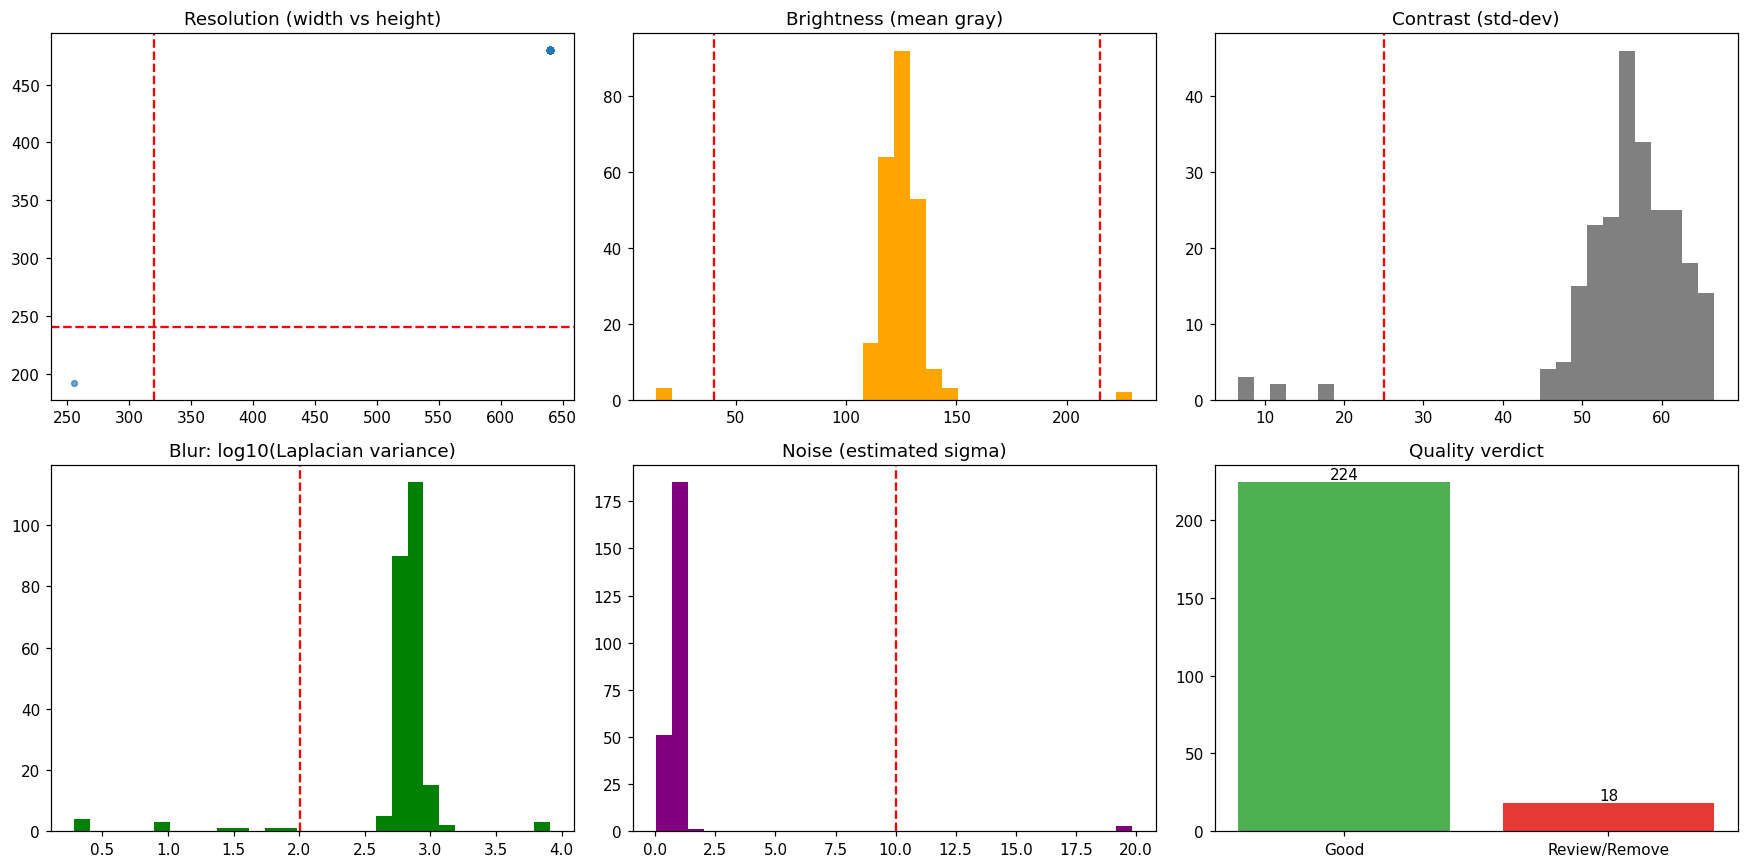

Why images need review/removal:
quality_reasons
blurry            11
low contrast       7
noisy              3
too dark           3
too bright         2
corrupt            2
low resolution     2


In [7]:
ok = df_img.dropna(subset=["brightness"])
if len(ok):
    print("Image-quality statistics:")
    print(ok[["width", "height", "brightness", "contrast", "blur_var", "noise"]].describe().round(1).to_string(), "\n")
    print("Unique resolutions (top 10):")
    print(ok.groupby(["width", "height"]).size().sort_values(ascending=False).head(10).to_string())

    fig, axs = plt.subplots(2, 3, figsize=(16, 8))
    axs[0, 0].scatter(ok["width"], ok["height"], alpha=0.4, s=14); axs[0, 0].set_title("Resolution (width vs height)")
    axs[0, 0].axvline(MIN_WIDTH, c="r", ls="--"); axs[0, 0].axhline(MIN_HEIGHT, c="r", ls="--")
    axs[0, 1].hist(ok["brightness"], bins=30, color="orange"); axs[0, 1].set_title("Brightness (mean gray)")
    axs[0, 1].axvline(DARK_THRESHOLD, c="r", ls="--"); axs[0, 1].axvline(BRIGHT_THRESHOLD, c="r", ls="--")
    axs[0, 2].hist(ok["contrast"], bins=30, color="gray"); axs[0, 2].set_title("Contrast (std-dev)")
    axs[0, 2].axvline(CONTRAST_MIN, c="r", ls="--")
    axs[1, 0].hist(np.log10(ok["blur_var"] + 1), bins=30, color="green"); axs[1, 0].set_title("Blur: log10(Laplacian variance)")
    axs[1, 0].axvline(np.log10(BLUR_THRESHOLD + 1), c="r", ls="--")
    axs[1, 1].hist(ok["noise"], bins=30, color="purple"); axs[1, 1].set_title("Noise (estimated sigma)")
    axs[1, 1].axvline(NOISE_THRESHOLD, c="r", ls="--")
    vc = df_img["quality"].value_counts()
    axs[1, 2].bar(vc.index, vc.values, color=["#4caf50" if i == "Good" else "#e53935" for i in vc.index])
    axs[1, 2].bar_label(axs[1, 2].containers[0]); axs[1, 2].set_title("Quality verdict")
    plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/image_quality.png"); plt.show()

    print("Why images need review/removal:")
    rs = df_img[df_img["quality"] != "Good"]["quality_reasons"].str.split(", ").explode().value_counts()
    print(rs.to_string())

## 8. Issue report: every flagged item

In [8]:
if len(df_issues):
    print("Issue summary (count per split):")
    print(df_issues.groupby(["issue", "split"]).size().unstack(fill_value=0).to_string(), "\n")
    pd.set_option("display.max_colwidth", 90)
    print(df_issues.head(30).to_string())
else:
    print("No issues found. Dataset looks clean!")

Issue summary (count per split):
split                 test  train  val
issue                                 
blurry                   2      8    1
corrupt image            0      2    0
empty label file         0      2    1
invalid box              2      9    0
label without image      0      1    0
low contrast             1      5    1
low resolution           0      2    0
malformed line           0      1    0
missing label file       0      4    0
noisy                    0      2    1
non-numeric value        0      0    1
suspicious box shape     0      8    3
too bright               1      1    0
too dark                 0      2    1 

                                                         file  split               issue                                                                            detail
0     /content/VisionPort_Dataset/labels/test/vp_test_001.txt   test         invalid box                                                   line 10: coordinate outside 0-1

## 9. Visualisation: labelled images, good vs bad quality, annotation validation
Green = box OK, **red = flagged for review**.

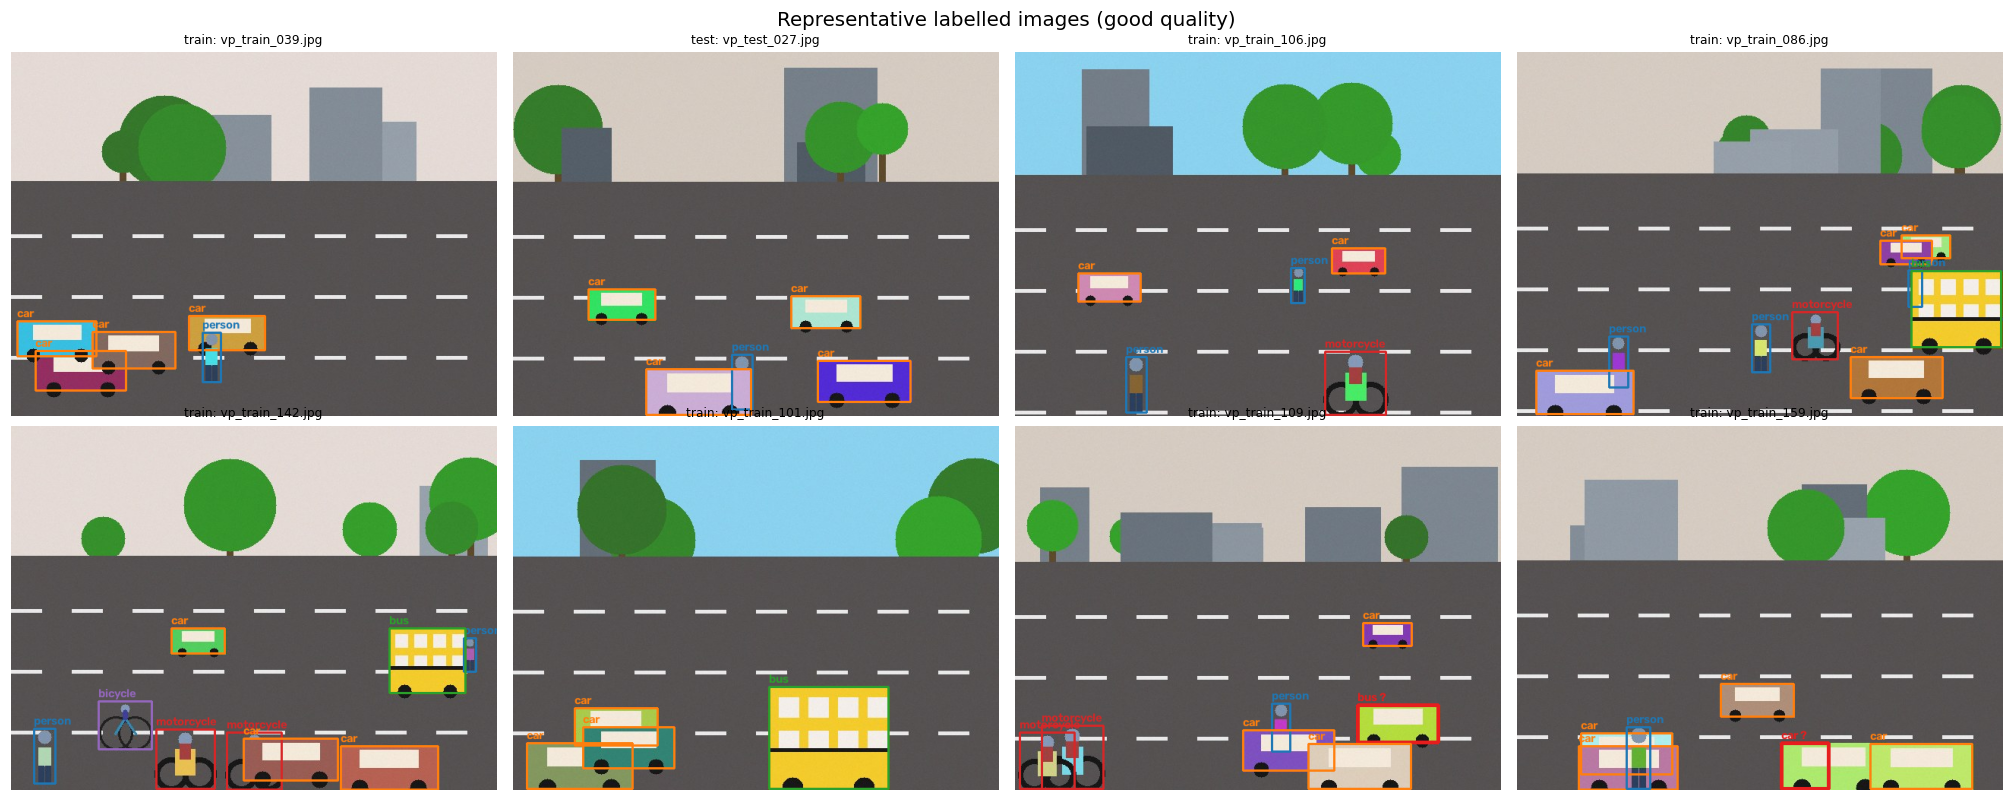

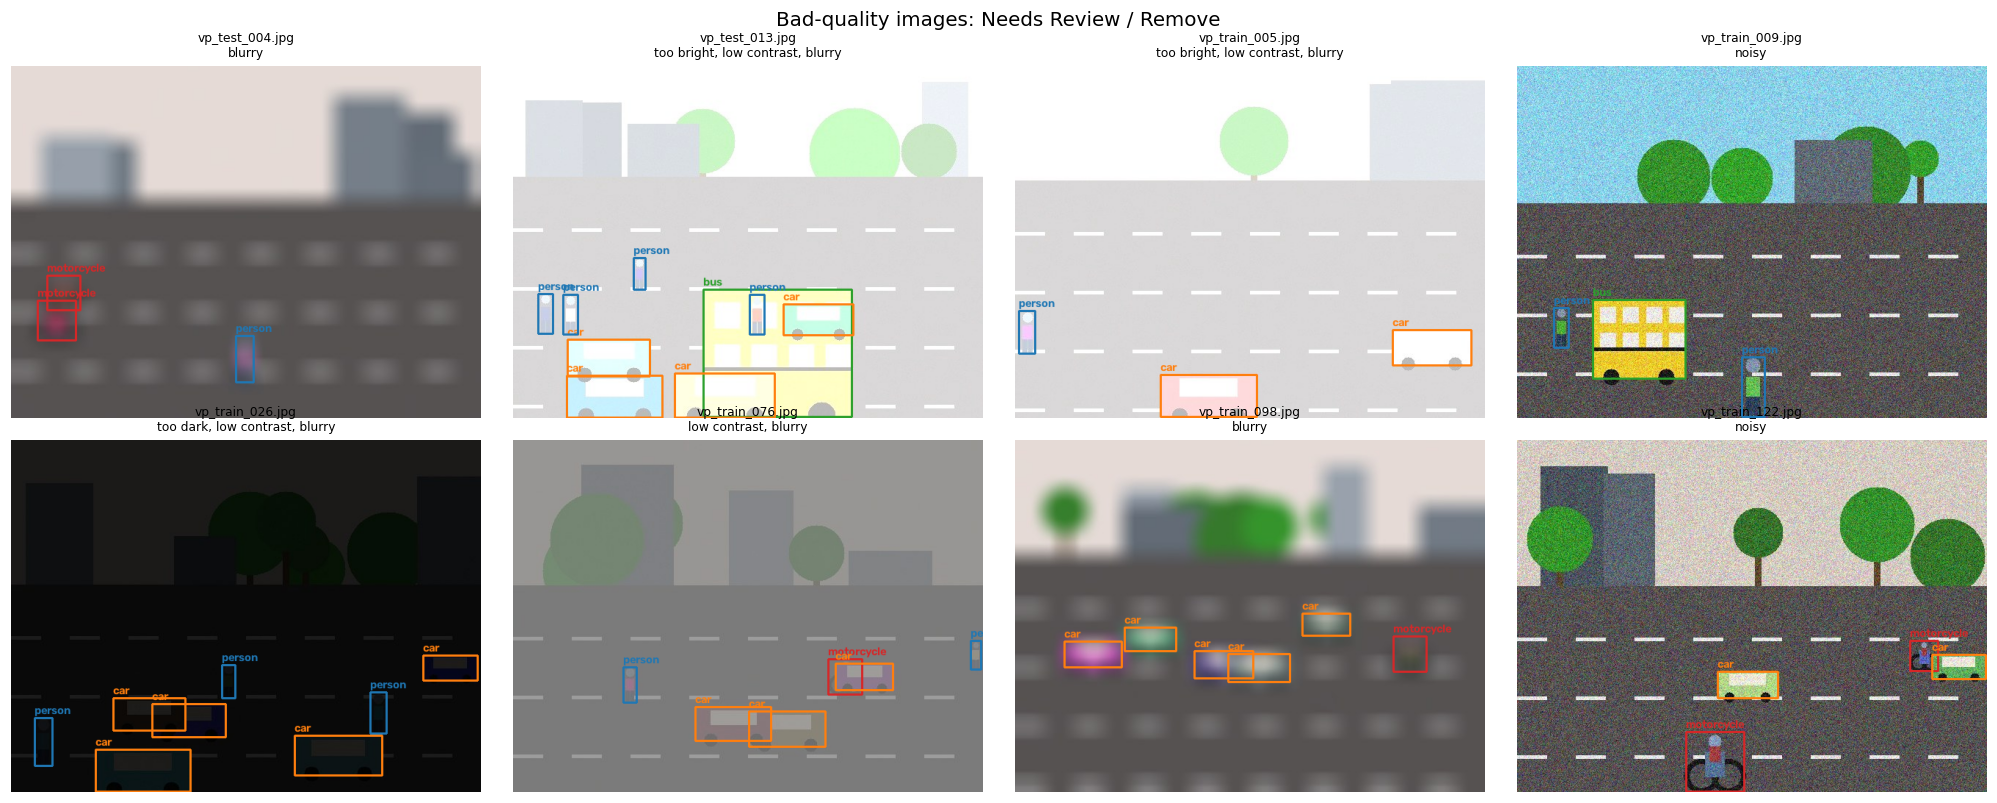

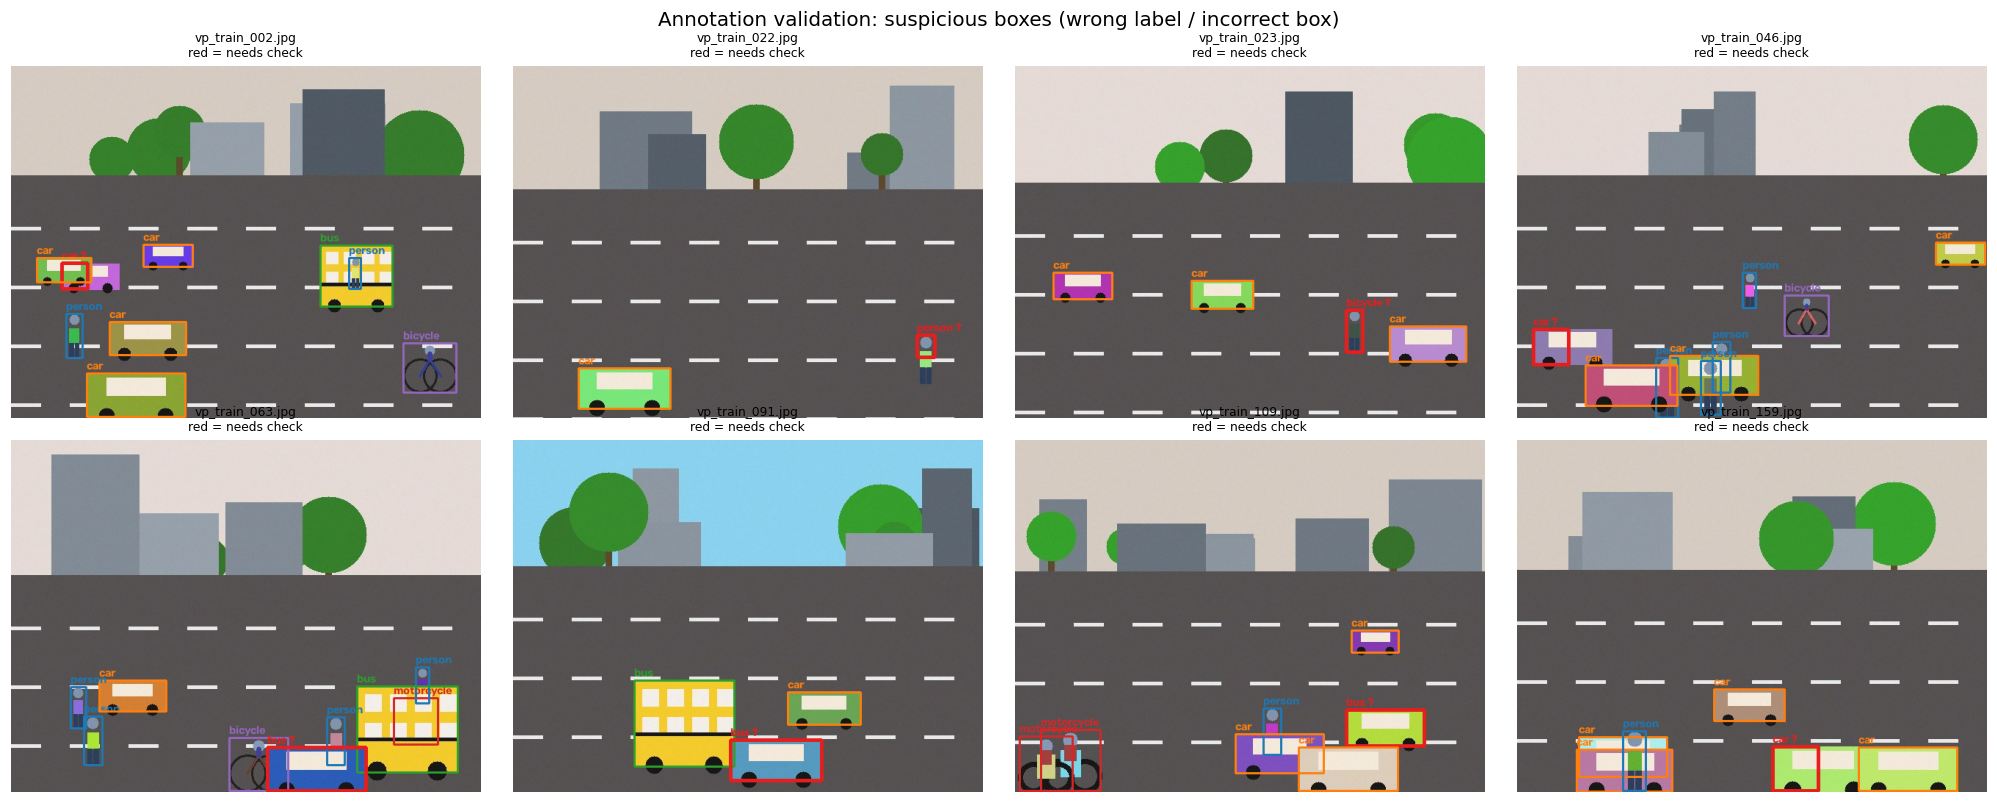

In [9]:
palette = [tuple(int(c * 255) for c in plt.cm.tab10(i % 10)[:3]) for i in range(max(NC or 1, 1))]

def draw(img_path, split=None):
    im = cv2.imread(str(img_path))
    if im is None: return None
    im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)          # draw in RGB so palette colours are correct
    H, W = im.shape[:2]
    lp = label_path_for(Path(img_path)); name = Path(img_path).name
    if lp.exists():
        for ln, line in enumerate([l for l in open(lp).read().splitlines() if l.strip()], 1):
            tok = line.split()
            if len(tok) != 5: continue
            try: c = int(float(tok[0])); x, y, w, h = map(float, tok[1:])
            except ValueError: continue
            x1, y1 = int((x - w/2) * W), int((y - h/2) * H); x2, y2 = int((x + w/2) * W), int((y + h/2) * H)
            flag = (split, name, ln) in flagged_boxes
            col = (230, 30, 30) if flag else palette[c % len(palette)]
            lab = (names[c] if 0 <= c < len(names) else str(c)) + (" ?" if flag else "")
            cv2.rectangle(im, (x1, y1), (x2, y2), col, max(2, W // 300) + (1 if flag else 0))
            cv2.putText(im, lab, (x1, max(y1 - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, max(0.5, W / 1400), col, 2)
    return im

def show_grid(rows, title, cols=4, fname=None, note=None):
    rows = list(rows)
    if not rows: print(f"{title}: nothing to show"); return
    nr = (len(rows) + cols - 1) // cols
    fig, axs = plt.subplots(nr, cols, figsize=(4.6 * cols, 3.7 * nr)); axs = np.array(axs).reshape(-1)
    for ax in axs: ax.axis("off")
    for ax, (path, split, cap) in zip(axs, rows):
        im = draw(path, split)
        if im is not None: ax.imshow(im); ax.set_title(cap, fontsize=8)
    fig.suptitle(title, fontsize=13); plt.tight_layout()
    if fname: plt.savefig(f"{OUTPUT_DIR}/{fname}")
    plt.show()

# (a) representative labelled images from every split
good = df_img[(df_img["quality"] == "Good") & (df_img["n_boxes"] > 0)]
smp = good.sample(min(N_SAMPLES, len(good)), random_state=3)
show_grid([(r["image"], r["split"], f"{r['split']}: {r['name']}") for _, r in smp.iterrows()],
          "Representative labelled images (good quality)", fname="samples_good.png")

# (b) bad-quality images needing review / removal
bad = df_img[(df_img["quality"] != "Good") & (~df_img["corrupt"])]
show_grid([(r["image"], r["split"], f"{r['name']}\n{r['quality_reasons']}") for _, r in bad.head(8).iterrows()],
          "Bad-quality images: Needs Review / Remove", fname="samples_bad_quality.png")

# (c) annotation validation: flagged boxes in red
fl_names = sorted({(s, n) for s, n, _ in flagged_boxes})[:8]
rows = []
for s, n in fl_names:
    if (s, n) in img_lookup: rows.append((str(img_lookup[(s, n)]), s, f"{n}\nred = needs check"))
show_grid(rows, "Annotation validation: suspicious boxes (wrong label / incorrect box)", fname="samples_flagged_annotations.png")

## 10. Audit summary, class imbalance and verdict

In [10]:
lines = []
def P(s=""): print(s); lines.append(s)

n_hard = 0
if len(df_issues):
    hard_kinds = {"corrupt image", "missing label file", "invalid box", "malformed line", "non-numeric value", "label without image"}
    n_hard = int(df_issues["issue"].isin(hard_kinds).sum())

P("=" * 62); P("VISIONPORT DATASET AUDIT SUMMARY"); P("=" * 62)
P(f"Dataset path          : {DATASET_DIR}")
P(f"Total images          : {len(df_img)}")
for s, n in df_img["split"].value_counts().items(): P(f"   - {s:<6}            : {n}  ({n/len(df_img)*100:.0f}%)")
P(f"Total label files     : {len(all_label_files)}")
P(f"Total boxes           : {len(df_box)}   (valid: {int(df_box['valid'].sum()) if len(df_box) else 0})")
P(f"Good-quality images   : {int((df_img['quality']=='Good').sum())}")
P(f"Review/Remove images  : {int((df_img['quality']!='Good').sum())}")
P(f"Missing label files   : {int((~df_img['has_label']).sum())}")
P(f"Suspicious boxes      : {len(flagged_boxes)} (manual review)")
if len(df_issues):
    P(f"Total issues flagged  : {len(df_issues)}")
    for k, v in df_issues["issue"].value_counts().items(): P(f"   - {k:<22}: {v}")

if len(df_box):
    cc = class_counts[class_counts.index.isin(names)] if names else class_counts
    cc = cc.reindex(names).fillna(0).astype(int) if names else cc
    mx, mn = cc.max(), cc.min(); ratio = mx / max(mn, 1)
    P(); P("CLASS BALANCE")
    P(f"Most frequent  : {cc.idxmax()} ({mx} boxes)")
    P(f"Least frequent : {cc.idxmin()} ({mn} boxes)")
    P(f"Imbalance ratio (max/min): {ratio:.1f}x")
    minority = cc[cc < 0.1 * mx].index.tolist()
    if minority: P(f"Minority classes (<10% of largest): {minority}")
    P(); P("OBSERVATIONS")
    if ratio > 10:   P("- Severe class imbalance: the model will be biased towards the majority class.")
    elif ratio > 3:  P("- Moderate class imbalance: track per-class AP/recall, not only overall mAP.")
    else:            P("- Classes are reasonably balanced.")
    if minority:     P("- Fixes: collect more minority samples, augment (flip / colour / mosaic), class weights, oversample minority images.")
    if len(df_issues): P("- Fix or remove flagged items (issues.csv, images_review_remove.csv) before training.")
    if len(flagged_boxes): P("- Suspicious boxes: open them in the visualisation and correct the label or box.")
    if ok["width"].nunique() > 1: P("- Several resolutions present: resize/letterbox consistently (e.g. imgsz=640).")

P(); P("VERDICT")
P("NOT READY for training: fix the issues listed above." if (n_hard or len(flagged_boxes)) else "READY for training (minor quality notes only).")

with open(f"{OUTPUT_DIR}/audit_summary.txt", "w") as f: f.write("\n".join(lines))
df_img.to_csv(f"{OUTPUT_DIR}/images_summary.csv", index=False)
df_img[df_img["quality"] != "Good"][["image", "split", "quality_reasons"]].to_csv(f"{OUTPUT_DIR}/images_review_remove.csv", index=False)
df_box.to_csv(f"{OUTPUT_DIR}/boxes.csv", index=False)
pd.DataFrame(issues).to_csv(f"{OUTPUT_DIR}/issues.csv", index=False)
if len(df_box): class_counts.rename("boxes").to_csv(f"{OUTPUT_DIR}/class_counts.csv")

VISIONPORT DATASET AUDIT SUMMARY
Dataset path          : /content/VisionPort_Dataset
Total images          : 242
   - train             : 170  (70%)
   - test              : 36  (15%)
   - val               : 36  (15%)
Total label files     : 239
Total boxes           : 1291   (valid: 1281)
Good-quality images   : 224
Review/Remove images  : 18
Missing label files   : 4
Suspicious boxes      : 11 (manual review)
Total issues flagged  : 62
   - invalid box           : 11
   - blurry                : 11
   - suspicious box shape  : 11
   - low contrast          : 7
   - missing label file    : 4
   - noisy                 : 3
   - empty label file      : 3
   - too dark              : 3
   - too bright            : 2
   - corrupt image         : 2
   - low resolution        : 2
   - malformed line        : 1
   - non-numeric value     : 1
   - label without image   : 1

CLASS BALANCE
Most frequent  : car (662 boxes)
Least frequent : bicycle (49 boxes)
Imbalance ratio (max/min): 13.5x
Min

## 11. Export: download the audit results

In [ ]:
shutil.make_archive("/content/visionport_audit", "zip", OUTPUT_DIR)
try:
    from google.colab import files
    files.download("/content/visionport_audit.zip")
except ImportError:
    print("Saved to /content/visionport_audit.zip")